<center><h1>Xie_Anna_HW4</h1></center>
<br>
<br>

Name: Anna Xie
<br>
Github Username: annajxiee
<br>
USC ID: 2277255370

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [31]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import statsmodels.api as sm
from sklearn.svm import LinearSVC
from sklearn.exceptions import ConvergenceWarning
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.metrics import (confusion_matrix, accuracy_score, roc_curve, roc_auc_score, auc, ConfusionMatrixDisplay)

Get the AReM Data Set

In [19]:
# (a) Get the AReM Data Set
data_root = '../data'
activities = ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']
cols = ['time', 'avg_rss12', 'var_rss12', 'avg_rss13', 'var_rss13', 'avg_rss23', 'var_rss23']

# descrition: reads one file and returns it as a cleaned table
# input: data path (like one to each dataset.csv)
# output: a cleaned pd.df
def load_instance(path):
    df = pd.read_csv(path, comment='#', header=None, names=cols,
                     sep=r'[,\s]+', engine='python', usecols=range(7))
    df = df.drop(columns='time')
    assert df.shape[1] == 6, f'{path}: expected 6 columns, got {df.shape[1]}'
    # helps me check if the amt. of columsn isn't 6
    if df.shape[0] != 480:
        print(f'note: {path} has {df.shape[0]} rows instead of 480')
    return df

instances = []   # (activity, file_num, dataframe)
# for every activity that was measured, flip through the folder for every dataset.csv
for activity in activities:
    folder = os.path.join(data_root, activity)
    # build the folder path and .join inserts the right slash to specify root path
    for f in os.listdir(folder):
        # for every filename in folder, 
        # make sure the if skips anything that isn't a CSV
        if f.endswith('.csv'):
            file_num = int(f.replace('dataset', '').replace('.csv', ''))
            # pulls the number out of the filename and the int turns it into a number so we can keep track of which instance the data belongs to
            instances.append((activity, file_num, load_instance(os.path.join(folder, f))))
            # loads the file and stores a tuple of the label, the file number, and the associated data frame 

print(len(instances))
print(instances)

note: ../data\sitting\dataset8.csv has 479 rows instead of 480
88
[('bending1', 1,      avg_rss12  var_rss12  avg_rss13  var_rss13  avg_rss23  var_rss23
0        39.25       0.43      22.75       0.43      33.75        1.3
1        39.25       0.43      23.00       0.00      33.00        0.0
2        39.25       0.43      23.25       0.43      33.00        0.0
3        39.50       0.50      23.00       0.71      33.00        0.0
4        39.50       0.50      24.00       0.00      33.00        0.0
..         ...        ...        ...        ...        ...        ...
475      43.33       0.47      25.00       0.00      30.00        0.0
476      43.50       0.50      25.50       0.50      30.00        0.0
477      43.50       0.50      24.75       0.43      30.00        0.0
478      43.50       0.50      24.33       0.47      30.00        0.0
479      43.50       0.50      24.25       0.43      30.00        0.0

[480 rows x 6 columns]), ('bending1', 2,      avg_rss12  var_rss12  avg_rss1

### (b) Splitting Data

In [20]:
# (b) Test and Train Data
training, testing = [], []

# for every activity instance in the dataset, unpack each item into three sections
# make sure the df can be split based on criteria
# dataset1+2.csv from bending1+2 and datasets1+2+3.csv => test
# everything else => train
for activity, file_num, df in instances:
    # bending1+2 should specifically be dataset 1 and 2, but otherwise its dataset1-3
    n_test = 2 if activity in ('bending1', 'bending2') else 3
    (testing if file_num <= n_test else training).append((activity, file_num, df))

print(f'{len(training)} train instances, {len(testing)} test instances')   # 69 and 19

69 train instances, 19 test instances


### (c) Feature Extraction

In [21]:
# extract the min, max, mean, median, sd, Q1, and Q3 from each instance's 6 cols 

# for each csv file, summarize each col into 7 numbers
# new structure: every row is one csv file, every column is one stat number 

# first get everything out of the dataframe
# description: extracts each column grouped by instance number and creates a dictionary of domain features
# input: dataframe
# output: features dictionary
def extract(df, l=1):
  feats = {}
  for i, col in enumerate(df.columns, start=1):                 
      pieces = np.array_split(df[col].to_numpy(), l)            
      for j, seg in enumerate(pieces, start=1):                 
          tag = f'{i}' if l == 1 else f'{i}_{j}'                
          feats[f'min{tag}'] = seg.min()
          feats[f'max{tag}'] = seg.max()
          feats[f'mean{tag}'] = seg.mean()
          feats[f'median{tag}'] = np.median(seg)
          feats[f'std{tag}'] = seg.std(ddof=1)                  
          feats[f'1st_quart{tag}'] = np.percentile(seg, 25)
          feats[f'3rd_quart{tag}'] = np.percentile(seg, 75)
  return feats

# description: builds data frame of domain-features relative to the instance (1 out of 88)
# input: instances (the og training/testing df)
# output: a new df w extracted time-domain features per instance 
def build_feats_table(instances, l=1):
  rows = []
  for activity, file_num, df in instances:
    row = {'activity': activity, 'file_num': file_num, 'bending': int(activity in ('bending1', 'bending2'))}
    row.update(extract(df, l))
    rows.append(row)

  return pd.DataFrame(rows)

training_new = build_feats_table(training)
testing_new = build_feats_table(testing)

all_features = pd.concat([training_new, testing_new], ignore_index=True)
all_features.insert(0, 'Instance', range(1, len(all_features) + 1))

# print(training_new.shape, testing_new.shape, all_features.shape)   # (69, 44) (19, 44) (88, 44)
# all_features.head()
# print(all_features.shape)
# print(all_features)

# standard deviation part too
# estimate the standard deviation of each of the time-domain features you extracted from the data 
# use python boostrapped to build a 90% CI for sd of each feature 

# isolate the feature names themselves
# from the finished df, get only the feat names so not activity, Instance, or file_num
feat_cols = [c for c in all_features.columns if c not in ('Instance', 'activity', 'file_num', 'bending')]
# print(feat_cols)

X = all_features[feat_cols].values
# print(type(X))
r, c = X.shape
# r = rows, c = cols

nan_counts = all_features[feat_cols].isna().sum()
print(nan_counts[nan_counts > 0])          # which features contain NaN, and how many

rows = all_features[feat_cols].isna().any(axis=1)
print(all_features.loc[rows, ['Instance', 'activity', 'file_num']])   # which instances 
# point estimate: sample stf of each feat
point_std = X.std(axis=0, ddof=1)

# bootstrap: resample 88 instances w replacement,
# recompute every features's standard deviation,
# repeat a certain number of times 
#spread of sd will show how uncertain the estimate iss 
num = np.random.default_rng(42)
times = 2000
boot_stds = np.empty((times, c))

boot_stds = np.array([
    X[num.integers(0, r, size=r)].std(axis=0, ddof=1)
    for _ in range(times)
])

print(boot_stds.shape, np.isnan(boot_stds).sum())
# print(boot_stds)
print(point_std)

# 90% percentile interval: 5% and 95% 
lower = np.percentile(boot_stds, 5, axis=0)
upper = np.percentile(boot_stds, 95, axis=0)

ci_table = pd.DataFrame({
  'std': point_std,
  'ci_lower': lower,
  'ci_upper': upper
}, index=feat_cols)

ci_table.round(4)
# print(type(point_std), type(lower), type(upper))
# print(np.isnan(boot_stds).sum())    # should be 0
# print(boot_stds.shape)              # should be (2000, 42)
# print(np.isnan(X).sum(), X.shape, X.dtype)              # expect 0, (88, 42), float64
# print((np.isnan(boot_stds).sum(axis=1) > 0).sum())     # how many bootstrap rows contain NaN
# print(np.isnan(boot_stds).sum(axis=0))                 # NaN count per feature
print("Three most important things I said were important: mean, standard deviation amd max")

Series([], dtype: int64)
Empty DataFrame
Columns: [Instance, activity, file_num]
Index: []
(2000, 42) 0
[9.56997528 4.39436168 5.33571766 5.44005414 1.7721534  6.15358972
 5.13892461 0.         5.06272937 1.57416392 1.41224416 0.88410548
 0.94638619 2.12526641 2.95646206 4.87513669 4.00838013 4.03639632
 0.94671026 4.22065788 4.17162822 0.         2.18362548 1.16611409
 1.14558566 0.4582417  0.84361968 1.55250418 6.12400143 5.7412383
 5.6755932  5.81378244 1.02489791 6.0964652  5.53172022 0.04583815
 2.51892098 1.15481192 1.08647433 0.51761747 0.75858382 1.52359913]
Three most important things I said were important: mean, standard deviation amd max


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

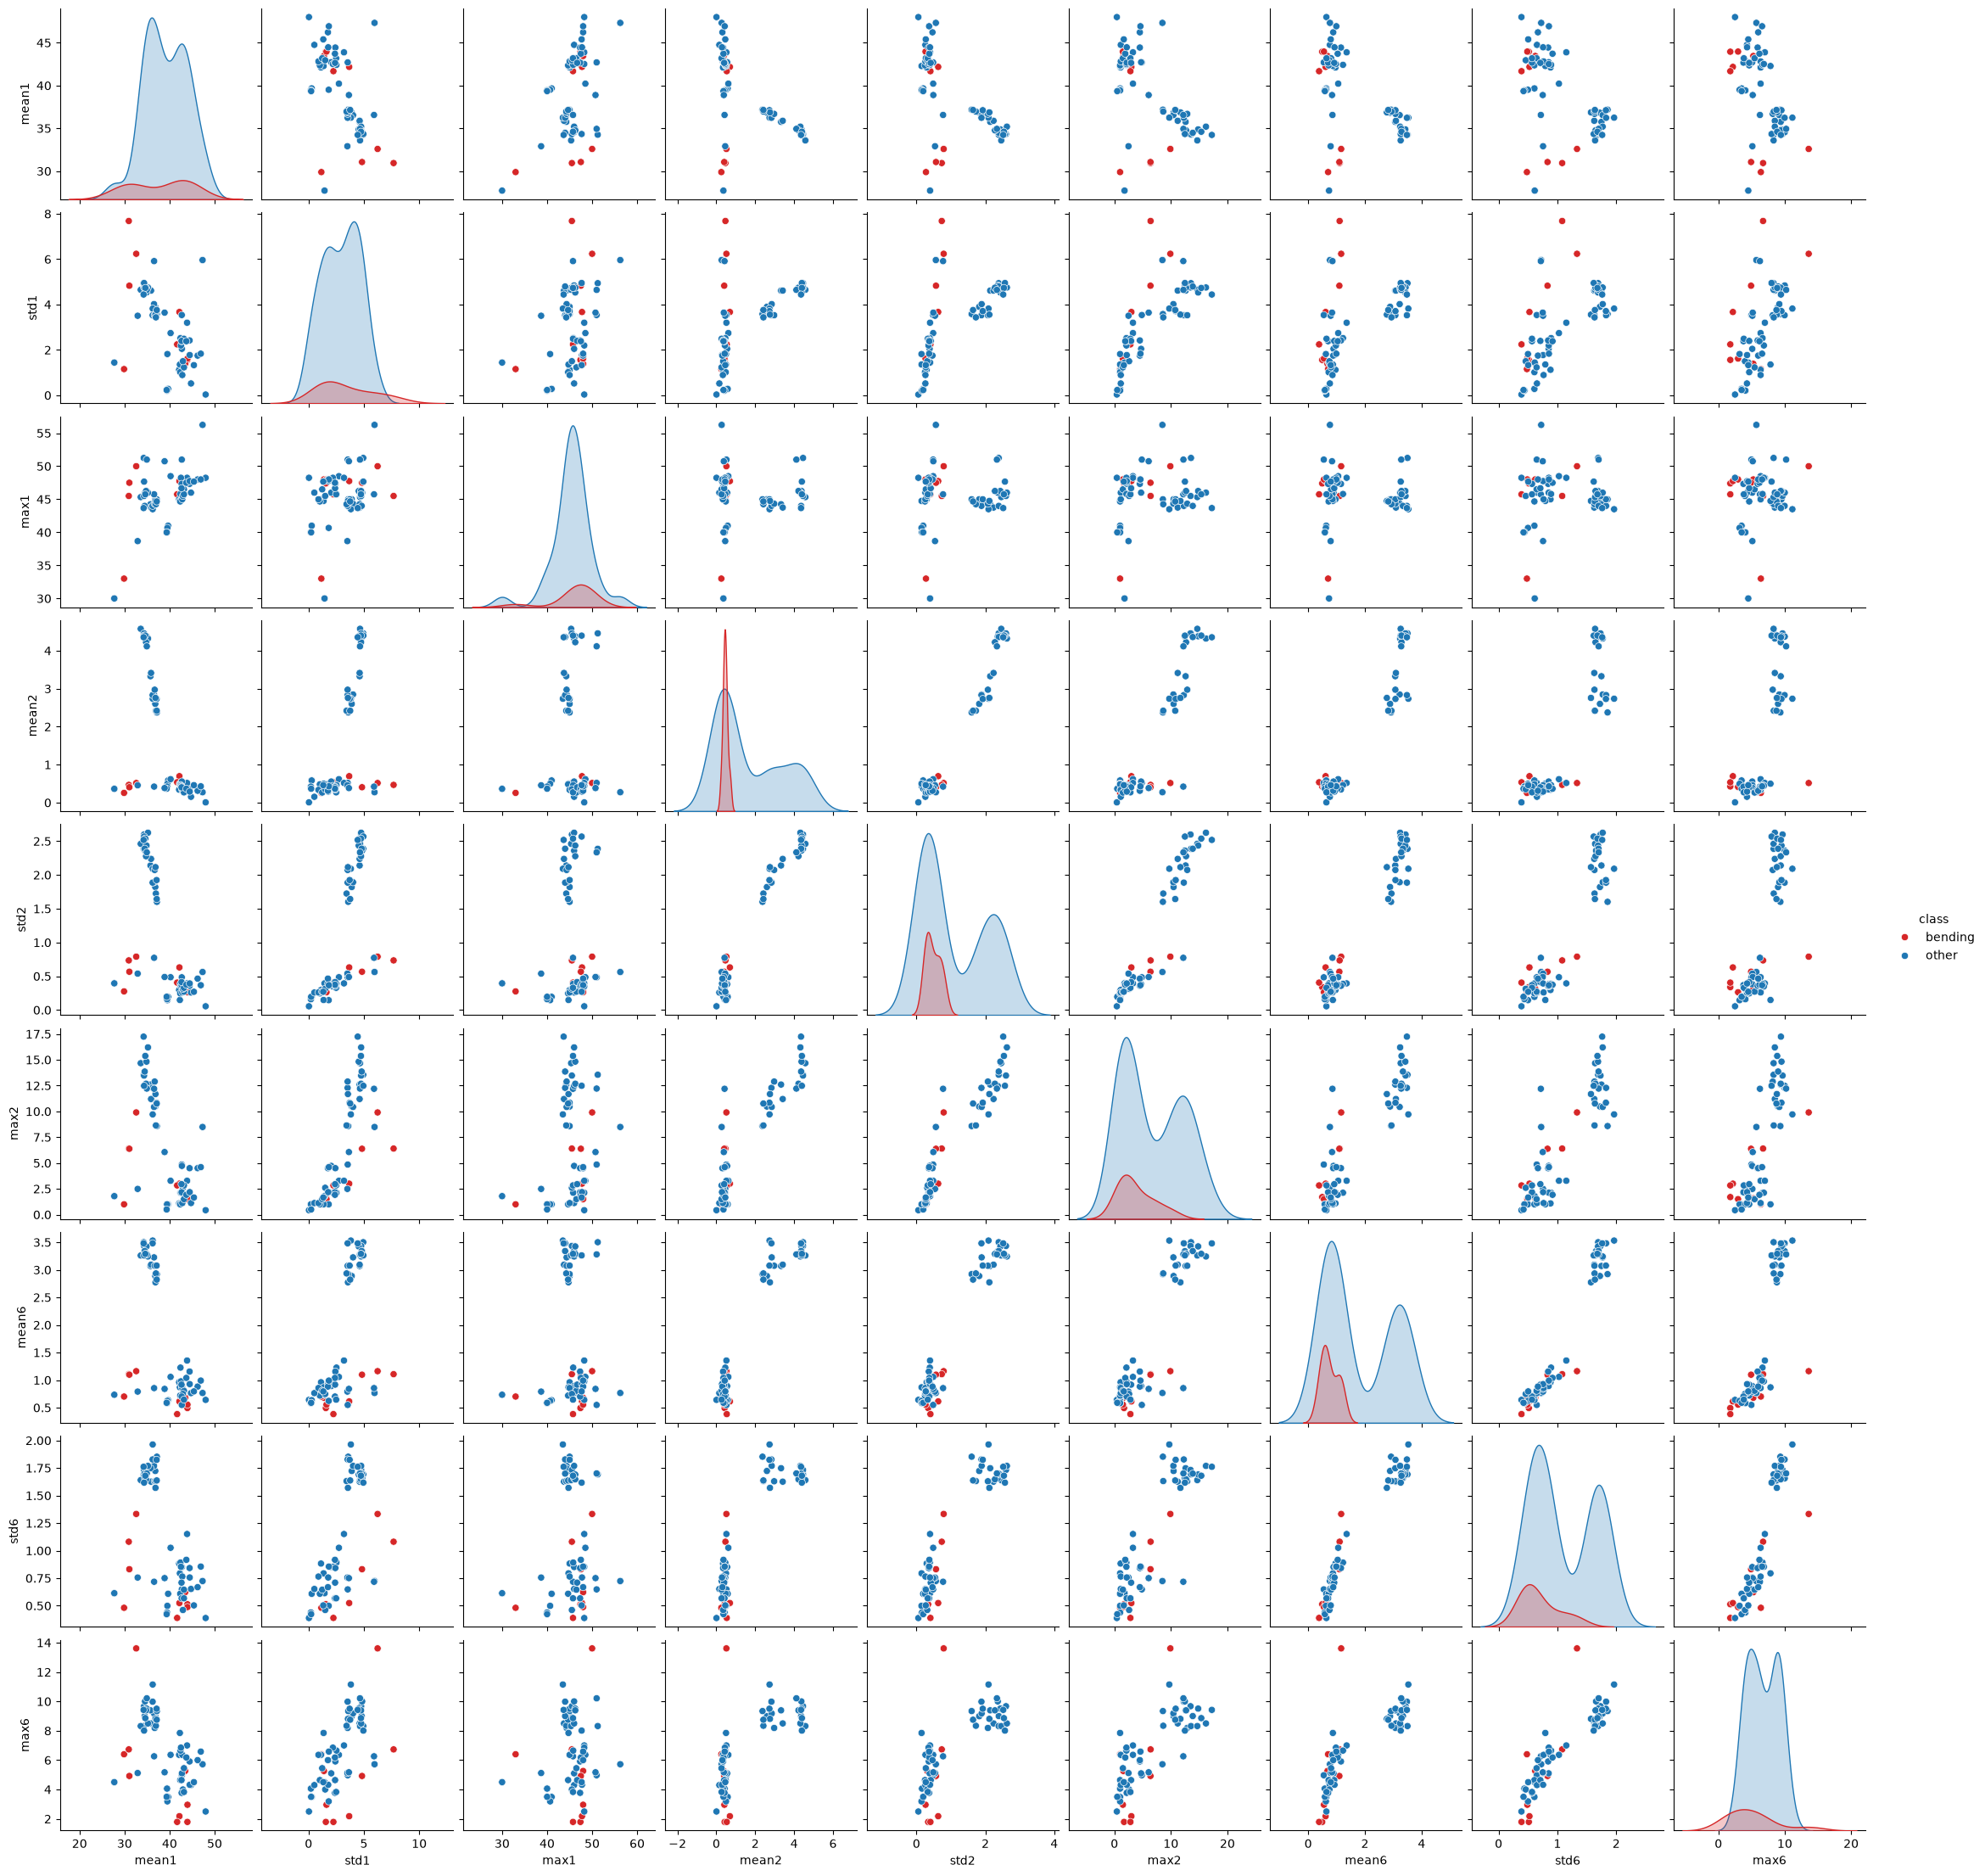

In [22]:
# assume you want to use the training set to classify bending from other activities (classify bending/not bending)
# depict scatter plots of mean, sd, and max from time series 1, 2, ad 6 of each instance
# use color to distinguish bending vs other activities

selected_cols = [
  'mean1', 'std1', 'max1',
  'mean2', 'std2', 'max2',
  'mean6', 'std6', 'max6'
]

plot_df = training_new.copy()
plot_df['class'] = plot_df['bending'].map({0: 'other', 1: 'bending'})
sns.pairplot(plot_df, vars=selected_cols, hue='class',
             palette={'other': 'tab:blue', 'bending': 'tab:red'})

#### ii. Splitted Plots

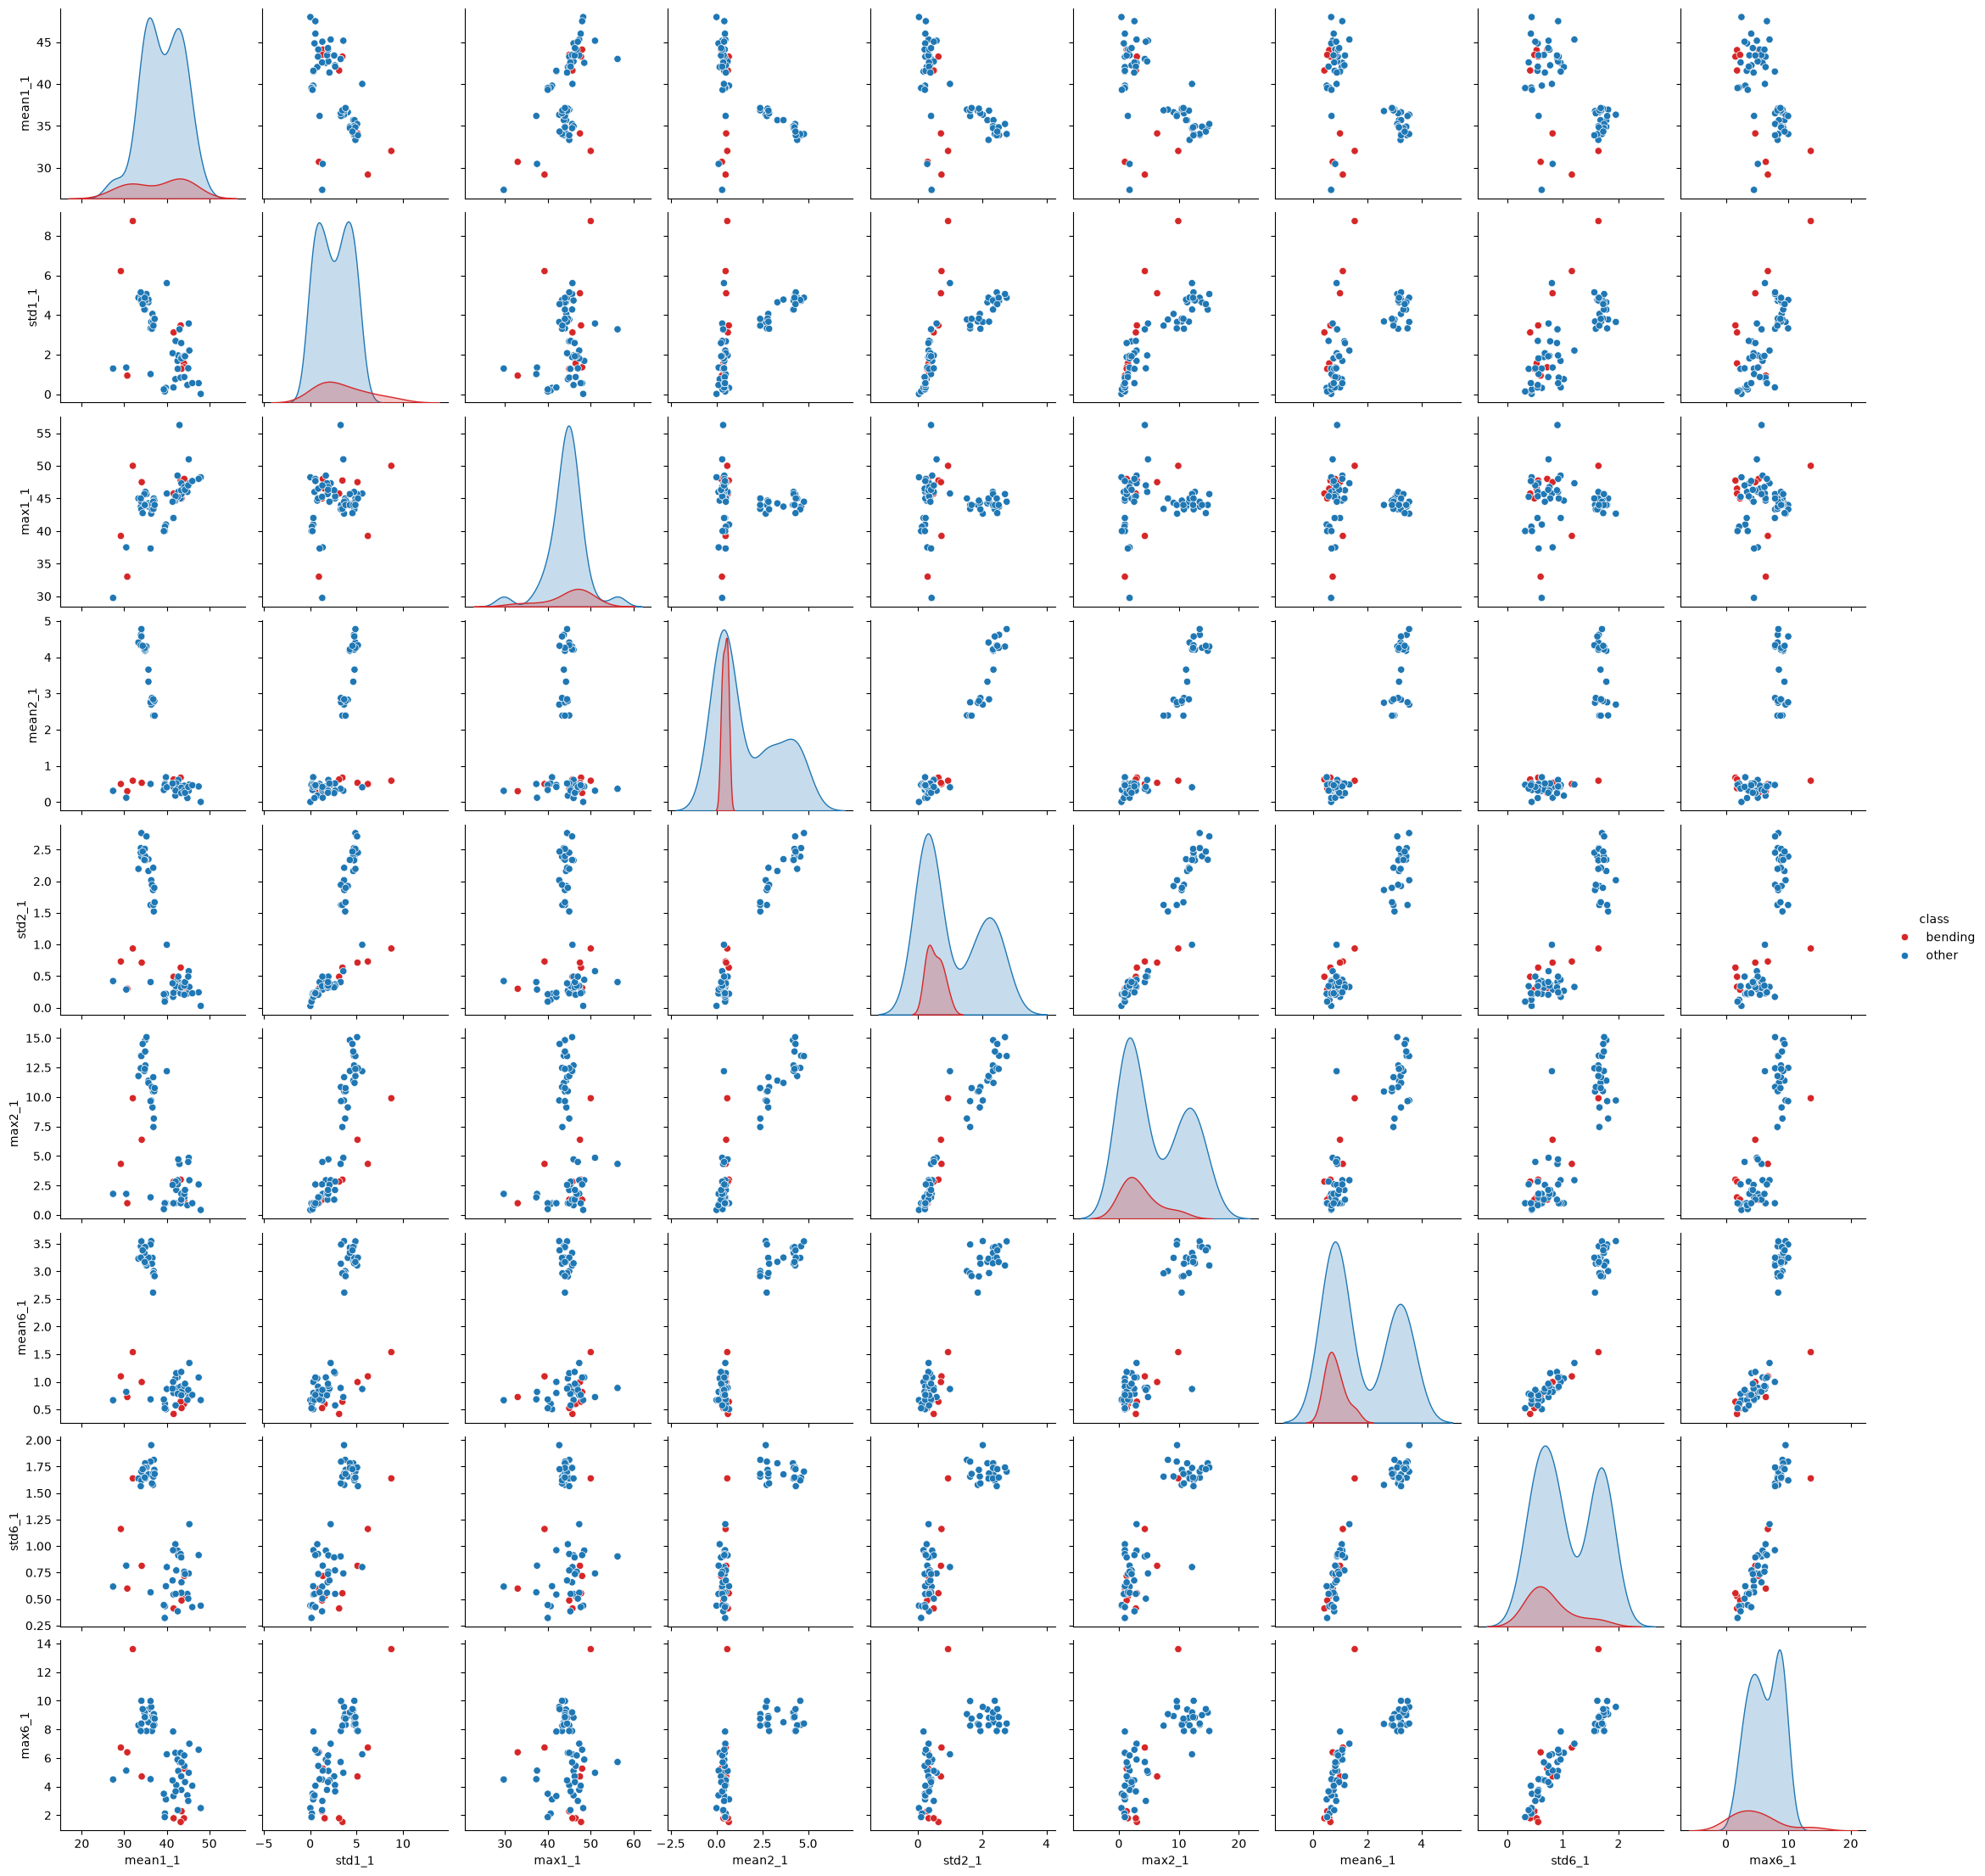

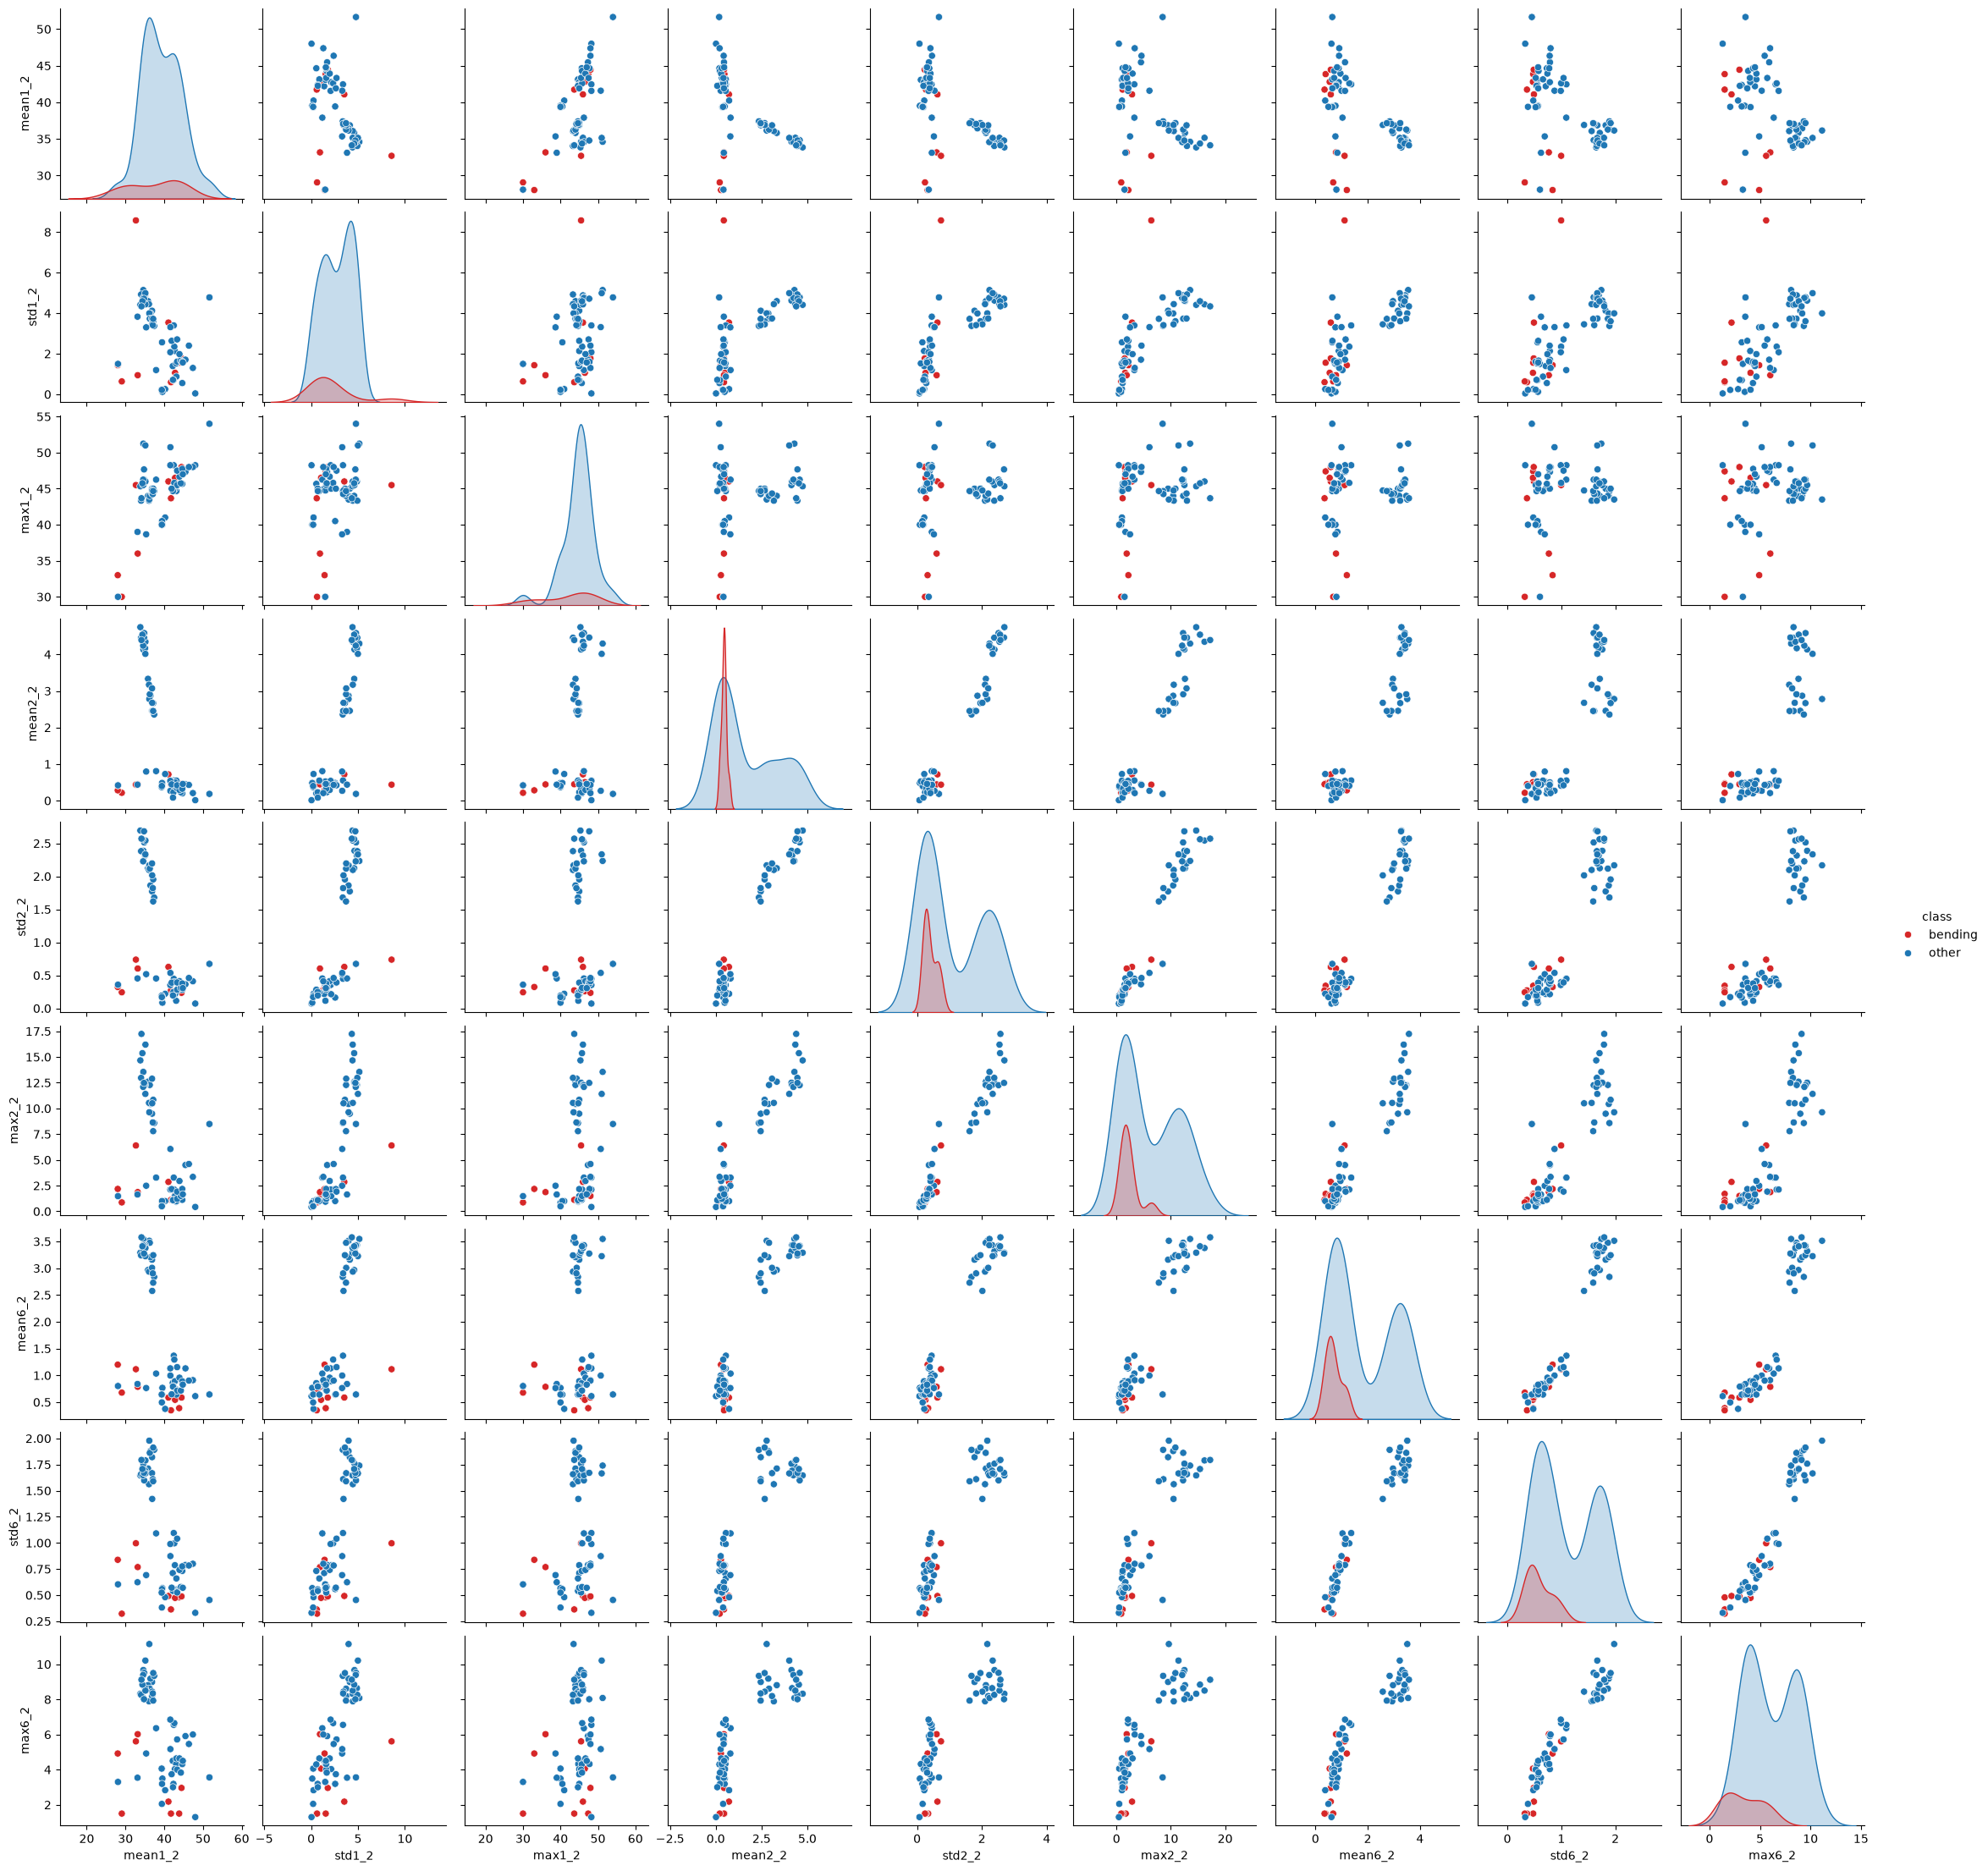

In [23]:
# split the instances
train_l2 = build_feats_table(training, l=2)
train_l2['class'] = train_l2['bending'].map({0:'other', 1:'bending'})

half1_cols = [f'{t}{s}_1' for s in (1,2,6) for t in ('mean', 'std', 'max')]
half2_cols = [f'{t}{s}_2' for s in (1,2,6) for t in ('mean', 'std', 'max')]

pal = {'other': 'tab:blue', 'bending': 'tab:red'}
first_plot = sns.pairplot(train_l2, vars=half1_cols, hue='class', palette=pal)
second_plot = sns.pairplot(train_l2, vars=half2_cols, hue='class', palette=pal)

#### iii. Time Series Segments

(69, 45) (69, 87) (69, 843)
l         1.000000
p         5.000000
cv_acc    0.985714
Name: 3, dtype: float64


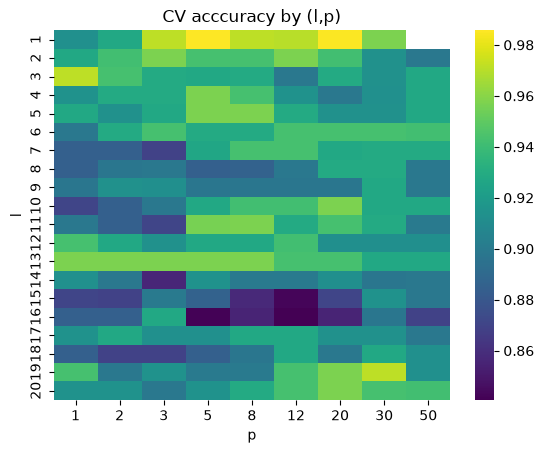

In [24]:
warnings.filterwarnings('ignore', category=ConvergenceWarning)

# split into l {1,2,...20}
train_by_l = {l: build_feats_table(training, l) for l in range(1, 21)}
test_by_l  = {l: build_feats_table(testing, l)  for l in range(1, 21)}

print(train_by_l[1].shape, train_by_l[2].shape, train_by_l[20].shape)

all_stats = ['min', 'max', 'mean', 'std', '1st_quart', '2nd_quart']
selected_stats = ['max', 'mean', 'std']

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
label_cols = ['activity', 'file_num', 'bending']
p_options = [1,2,3,5,8,12,20,30,50]

rows = []
for l in range(1,21):
  X = train_by_l[l].drop(columns=label_cols)
  y = train_by_l[l]['bending']

  for p in p_options:
    if p > X.shape[1]:
      continue

    pipe = Pipeline([
      ('scale', StandardScaler()),
      ('rfe', RFE(LogisticRegression(C=1e10, max_iter=200), n_features_to_select=p, step=0.1)),
      ('clf', LogisticRegression(C=1e10, max_iter=200))
    ])

    scores = cross_val_score(pipe, X, y, cv=skf, scoring='accuracy', n_jobs=-1)
    rows.append({'l':l, 'p':p, 'cv_acc':scores.mean()})

cv_results = pd.DataFrame(rows)
best = cv_results.sort_values(['cv_acc', 'l', 'p'], ascending=[False, True, True]).iloc[0]
best_l, best_p = int(best['l']), int(best['p'])

print(best)

sns.heatmap(cv_results.pivot(index='l', columns='p', values='cv_acc'), cmap='viridis')
plt.title('CV acccuracy by (l,p)')
plt.show()

# make a final model from cross validated features
Xtr = train_by_l[best_l].drop(columns=label_cols)
ytr = train_by_l[best_l]['bending']
Xte = test_by_l[best_l][Xtr.columns]          # same columns in the same order as train
yte = test_by_l[best_l]['bending']

final = Pipeline([
    ('scale', StandardScaler()),
    ('rfe', RFE(LogisticRegression(C=1e10, max_iter=200), n_features_to_select=best_p, step=0.1)),
    ('clf', LogisticRegression(C=1e10, max_iter=200)),
]).fit(Xtr, ytr)

pred_tr = final.predict(Xtr)
proba_tr = final.predict_proba(Xtr)[:, 1]

#### iv. Confusion Matrix

train confusion matrix: 
 [[60  0]
 [ 0  9]]


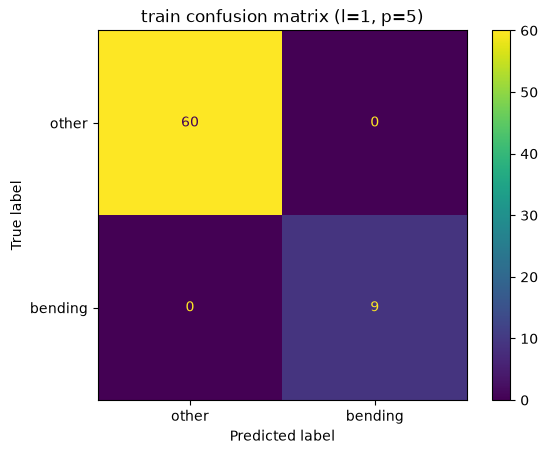

c:\Users\annax\anaconda3\Lib\site-packages\statsmodels\discrete\discrete_model.py:2385: RuntimeWarning: overflow encountered in exp
  return 1/(1+np.exp(-X))
c:\Users\annax\anaconda3\Lib\site-packages\statsmodels\discrete\discrete_model.py:2443: RuntimeWarning: divide by zero encountered in log
  return np.sum(np.log(self.cdf(q * linpred)))


statsmodels could not fit (likely separation): Singular matrix
3rd_quart1   -6.159594
min5          6.129920
max5          6.767448
mean5         3.429623
1st_quart6   -4.100330
dtype: float64


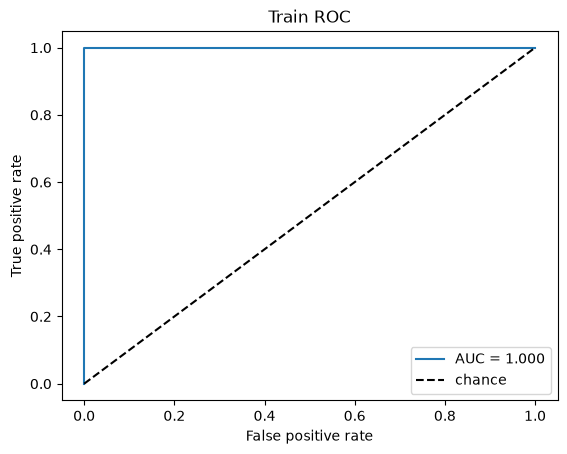

In [25]:
# make a confusion matrix

cm_tr = confusion_matrix(ytr, pred_tr)
print('train confusion matrix: \n', cm_tr)
ConfusionMatrixDisplay.from_predictions(ytr, pred_tr, display_labels=['other', 'bending'])
plt.title(f'train confusion matrix (l={best_l}, p={best_p})')
plt.show()

# ROC curve: tpr vs fpr
fpr, tpr, _ = roc_curve(ytr, proba_tr)
auc_tr = roc_auc_score(ytr, proba_tr)
fig, ax = plt.subplots(1,1)
ax.plot(fpr, tpr, label=f'AUC = {auc_tr:.3f}')
ax.plot([0,1], [0,1], 'k--', label='chance')
ax.set_xlabel('False positive rate')
ax.set_ylabel('True positive rate')
ax.set_title('Train ROC')
ax.legend()

# coefficients and pvalues
# refit the same selected features with statsmodels? 
mask = final.named_steps['rfe'].support_                     # which features RFE kept
sel_cols = list(Xtr.columns[mask])
Xs = pd.DataFrame(final.named_steps['scale'].transform(Xtr)[:, mask],
                  columns=sel_cols, index=Xtr.index)

try:
    logit = sm.Logit(ytr, sm.add_constant(Xs)).fit(disp=0, maxiter=100)
    print(logit.summary())                                   # betas, std errors, p-values
except Exception as e:                                       # perfect separation can break this fit
    print('statsmodels could not fit (likely separation):', e)
    print(pd.Series(final.named_steps['clf'].coef_[0], index=sel_cols))   # sklearn betas, no p-values

#### v. Test Classifier

Test confusion matrix:
 [[15  0]
 [ 0  4]]
Test sensitivity (bending caught): 1.00   specificity: 1.00
CV accuracy:   0.986
Test accuracy: 1.000
Always-"other" baseline: train 0.870, test 0.789


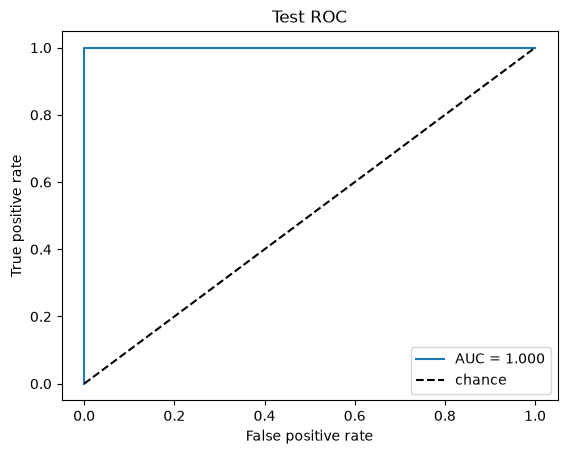

In [26]:
# The test features were built with the same l, and Xte has the same columns in the same
# order as Xtr, so the fitted pipeline (scaler + RFE + model) applies directly.
pred_te = final.predict(Xte)
proba_te = final.predict_proba(Xte)[:, 1]

cm_te = confusion_matrix(yte, pred_te)
print('Test confusion matrix:\n', cm_te)
tn, fp, fn, tp = cm_te.ravel()
print(f'Test sensitivity (bending caught): {tp / (tp + fn):.2f}   specificity: {tn / (tn + fp):.2f}')

fpr, tpr, _ = roc_curve(yte, proba_te)
auc_te = roc_auc_score(yte, proba_te)
fig, ax = plt.subplots(1,1)
ax.plot(fpr, tpr, label=f'AUC = {auc_te:.3f}')
ax.plot([0, 1], [0, 1], 'k--', label='chance')
ax.set_xlabel('False positive rate')
ax.set_ylabel('True positive rate')
ax.set_title('Test ROC')
ax.legend()

# Compare against cross-validation, and against doing nothing (always predicting "other")
print(f'CV accuracy:   {best["cv_acc"]:.3f}')
print(f'Test accuracy: {accuracy_score(yte, pred_te):.3f}')
print(f'Always-"other" baseline: train {1 - ytr.mean():.3f}, test {1 - yte.mean():.3f}')

#### vi. Separation

The classes do seem to be well separated. Because there's such a small amount of bending instances, I believe that will make predictions easier and more stable (not necessarily more correct) but the parameters in turn would be simpler to calculate

#### vii. Imbalance

Train class counts:
 bending
0    60
1     9
Name: count, dtype: int64
Test class counts:
 bending
0    15
1     4
Name: count, dtype: int64
Share of bending: train 0.13, test 0.21
population share = 0.130, sample share = 0.500
intercept: raw -7.625 -> adjusted -9.522
slopes (unchanged by the adjustment):
3rd_quart1   -2.540
min5          3.785
max5          4.773
mean5         3.171
1st_quart6   -5.784
dtype: float64
--- train ---
confusion matrix, intercept NOT adjusted:
 [[59  1]
 [ 0  9]]
confusion matrix, intercept adjusted:
 [[59  1]
 [ 0  9]]
--- test ---
confusion matrix, intercept NOT adjusted:
 [[15  0]
 [ 0  4]]
confusion matrix, intercept adjusted:
 [[15  0]
 [ 0  4]]


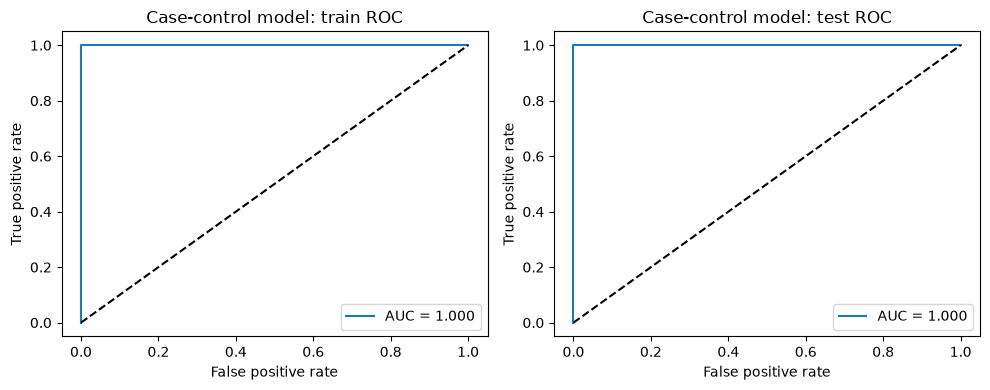

Based on the confusion matrices, the classes are imbalanced. There is a larger amount of non-bending instances than bending, even when I adjusted the intercepted for the purpose of equalizing them.


In [27]:
# build a logistic regression model based on case-control sampling and adjust its parameters 
# repeat confusion matrix, ROC, and AUC of the model

print('Train class counts:\n', ytr.value_counts())
print('Test class counts:\n', yte.value_counts())
print(f'Share of bending: train {ytr.mean():.2f}, test {yte.mean():.2f}')

# based on case control sampling (equalizing bending instances w non-bending instances)
# Standardized versions of just the features RFE kept (same scaler the pipeline learned)
scaler = final.named_steps['scale']
mask = final.named_steps['rfe'].support_
sel_cols = list(Xtr.columns[mask])
Xs_tr = pd.DataFrame(scaler.transform(Xtr)[:, mask], columns=sel_cols, index=Xtr.index)
Xs_te = pd.DataFrame(scaler.transform(Xte)[:, mask], columns=sel_cols, index=Xte.index)

# Case-control sampling: keep ALL cases (bending), randomly draw controls (other).
ratio = 1                                    # controls per case; 1 = balanced sample
rng = np.random.default_rng(0)
cases = ytr[ytr == 1].index
controls = rng.choice(ytr[ytr == 0].index, size=ratio * len(cases), replace=False)
cc_idx = cases.append(pd.Index(controls))

cc_model = LogisticRegression(C=1e10, max_iter=200).fit(Xs_tr.loc[cc_idx], ytr.loc[cc_idx])

# Sampling by outcome distorts only the intercept; the slopes stay valid. To get back to the
# real population, shift the intercept by the difference in log-odds of "bending":
#   beta0_adj = beta0 + log(pi / (1 - pi)) - log(pi_s / (1 - pi_s))
pi = ytr.mean()                              # true share of bending in the training data
pi_s = len(cases) / len(cc_idx)              # share of bending in the sample (0.5 when ratio = 1)
shift = np.log(pi / (1 - pi)) - np.log(pi_s / (1 - pi_s))

print(f'population share = {pi:.3f}, sample share = {pi_s:.3f}')
print(f'intercept: raw {cc_model.intercept_[0]:.3f} -> adjusted {cc_model.intercept_[0] + shift:.3f}')
print('slopes (unchanged by the adjustment):')
print(pd.Series(cc_model.coef_[0], index=sel_cols).round(3))

# visualize confusion matrix, ROC, AUC on the case controlled sampling data
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, X, y) in zip(axes, [('train', Xs_tr, ytr), ('test', Xs_te, yte)]):
    z_raw = cc_model.decision_function(X)    # log-odds under the balanced sample
    z_adj = z_raw + shift                    # log-odds after the intercept correction
    print(f'--- {name} ---')
    print('confusion matrix, intercept NOT adjusted:\n', confusion_matrix(y, (z_raw > 0).astype(int)))
    print('confusion matrix, intercept adjusted:\n', confusion_matrix(y, (z_adj > 0).astype(int)))

    # A constant shift doesn't change the ranking of instances, so the ROC curve and AUC are
    # identical with or without the adjustment.
    fpr, tpr, _ = roc_curve(y, z_adj)
    ax.plot(fpr, tpr, label=f'AUC = {roc_auc_score(y, z_adj):.3f}')
    ax.plot([0, 1], [0, 1], 'k--')
    ax.set(xlabel='False positive rate', ylabel='True positive rate',
           title=f'Case-control model: {name} ROC')
    ax.legend()
plt.tight_layout()
plt.show()

print('Based on the confusion matrices, the classes are imbalanced. There is a larger amount of non-bending instances than bending, even when I adjusted the intercepted for the purpose of equalizing them.')

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

c:\Users\annax\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\annax\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
c:\Users\annax\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 

l         1.000000
best_C    1.000000
cv_acc    0.985714
Name: 0, dtype: float64
l = 1, C = 1, nonzero coefficients: 7 of 42
max5          1.740
min5          1.100
1st_quart6   -0.636
3rd_quart1   -0.567
median6      -0.153
1st_quart4   -0.128
1st_quart3   -0.023
dtype: float64
Train confusion matrix:
 [[60  0]
 [ 0  9]]
Test confusion matrix:
 [[15  0]
 [ 0  4]]


c:\Users\annax\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\annax\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


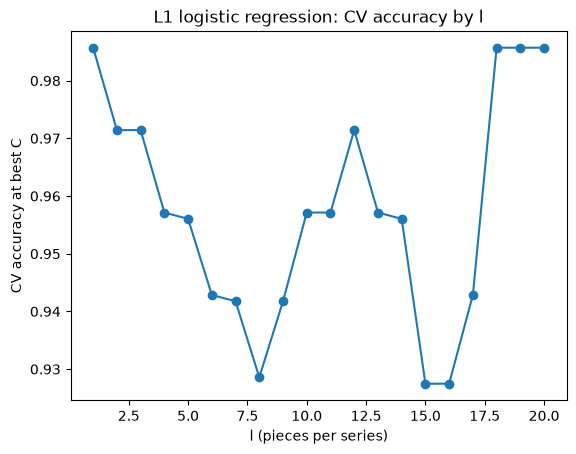

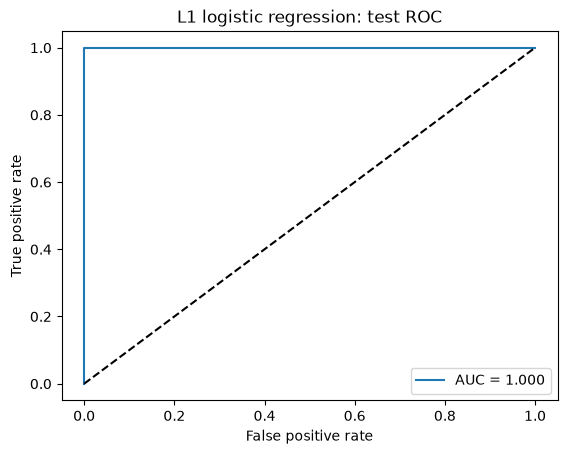

In [28]:
# cross validate both l and the penalty strength
# C is the inverse of lambda in sklearn
# meaning small C = large penalty (1/lambda)
Cs = np.logspace(-2, 2, 9)    

# standardizing should happen in a pipeline
l1_pipe = Pipeline([
  ('scale', StandardScaler()),
  ('clf', LogisticRegression(penalty='l1', solver='liblinear', max_iter=1000)),
])

rows, l1_models = [], {}
for l in range(1,21):
  X = train_by_l[l].drop(columns=label_cols)
  # calling label_cols from part a var
  y = train_by_l[l]['bending']

  # GridSearchCV cross-validates C for this l, then refits on the full training set with the best C
  gs = GridSearchCV(l1_pipe, {'clf__C': Cs}, cv=skf, scoring='accuracy', n_jobs=-1).fit(X, y)
  rows.append({'l': l, 'best_C': gs.best_params_['clf__C'], 'cv_acc': gs.best_score_})
  l1_models[l] = gs.best_estimator_

l1_results = pd.DataFrame(rows)
l1_best = l1_results.sort_values(['cv_acc', 'l'], ascending=[False, True]).iloc[0]   # ties -> smaller l
l1_l = int(l1_best['l'])
print(l1_best)

fig, ax = plt.subplots(1,1)

ax.plot(l1_results['l'], l1_results['cv_acc'], marker='o')
ax.set_xlabel('l (pieces per series)')
ax.set_ylabel('CV accuracy at best C')
ax.set_title('L1 logistic regression: CV accuracy by l')

# evaluting the models
# Evaluate the chosen model
m = l1_models[l1_l]
Xtr1 = train_by_l[l1_l].drop(columns=label_cols)
ytr1 = train_by_l[l1_l]['bending']
Xte1 = test_by_l[l1_l][Xtr1.columns]
yte1 = test_by_l[l1_l]['bending']

coefs = m.named_steps['clf'].coef_[0]
nonzero = int((coefs != 0).sum())
print(f'l = {l1_l}, C = {l1_best["best_C"]:.3g}, nonzero coefficients: {nonzero} of {len(coefs)}')
print(pd.Series(coefs, index=Xtr1.columns)[coefs != 0].sort_values(key=abs, ascending=False).head(10).round(3))

print('Train confusion matrix:\n', confusion_matrix(ytr1, m.predict(Xtr1)))
print('Test confusion matrix:\n',  confusion_matrix(yte1, m.predict(Xte1)))

fpr, tpr, _ = roc_curve(yte1, m.predict_proba(Xte1)[:, 1])
fig, ax = plt.subplots(1,1)
ax.plot(fpr, tpr, label=f'AUC = {roc_auc_score(yte1, m.predict_proba(Xte1)[:, 1]):.3f}')
ax.plot([0, 1], [0, 1], 'k--')
ax.set_xlabel('False positive rate')
ax.set_ylabel('True positive rate')
ax.set_title('L1 logistic regression: test ROC')
ax.legend()

#### ii. Comparison

In [29]:
comparison = pd.DataFrame({
    'method': ['RFE + logistic (2a)', 'L1 logistic (2b)'],
    'l': [best_l, l1_l],
    'features kept': [best_p, nonzero],
    'CV accuracy': [best['cv_acc'], l1_best['cv_acc']],
    'test accuracy': [accuracy_score(yte, final.predict(Xte)), accuracy_score(yte1, m.predict(Xte1))],
    'test AUC': [roc_auc_score(yte, final.predict_proba(Xte)[:, 1]),
                 roc_auc_score(yte1, m.predict_proba(Xte1)[:, 1])],
})
comparison.round(3)

,method,l,features kept,CV accuracy,test accuracy,test AUC
0,RFE + logistic (2a),1,5,0.986,1.0,1.0
1,L1 logistic (2b),1,7,0.986,1.0,1.0


From how both models performed, I would say the gap between evaluation alone isn't enough to cleanly state one method superior over the other in this case. In terms of complexity and setting it up, L1 is one pipeline and one GridSearch call whereas the RFE route needed a handwritten parameter and special handling. L1 had a lot of warnings during code executions too. L1 selects and shrinks in a single step whereas RFE was more manual. On a bigger scale, I can imagine L1 being more stable.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

c:\Users\annax\anaconda3\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
c:\Users\annax\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\annax\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
c:\Users\annax\anaconda3\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in

l         1.000000
best_C    3.162278
cv_acc    0.957143
Name: 0, dtype: float64
l = 1, C = 3.16, nonzero coefficients: 60 of 294
Train error: 0.000
Test error:  0.105


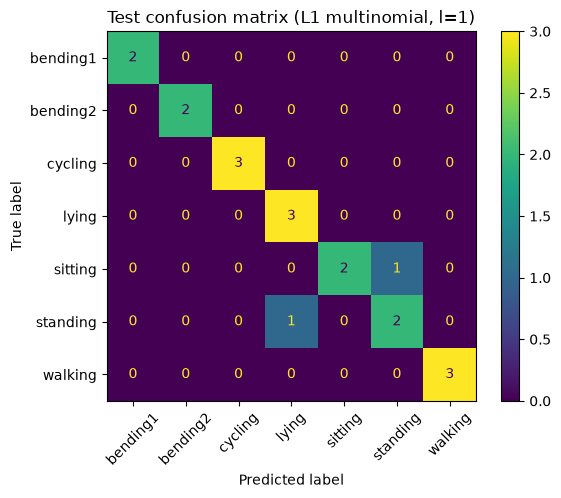

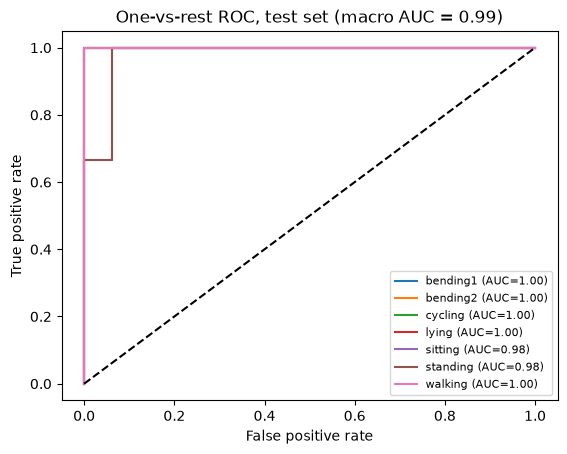

In [32]:
# For >2 classes, solver='saga' supports an L1 penalty AND fits a true multinomial (softmax) model.
# (liblinear would silently fall back to one-vs-rest.) Features are standardized inside the pipeline.
ml_pipe = Pipeline([
    ('scale', StandardScaler()),
    ('clf', LogisticRegression(penalty='l1', solver='saga', max_iter=3000, tol=1e-3)),
])

ml_rows, ml_models = [], {}
for l in range(1, 21):
    X = train_by_l[l].drop(columns=label_cols)
    y = train_by_l[l]['activity']                      # all 7 activities this time
    gs = GridSearchCV(ml_pipe, {'clf__C': Cs}, cv=skf, scoring='accuracy', n_jobs=-1).fit(X, y)
    ml_rows.append({'l': l, 'best_C': gs.best_params_['clf__C'], 'cv_acc': gs.best_score_})
    ml_models[l] = gs.best_estimator_

ml_results = pd.DataFrame(ml_rows)
ml_best = ml_results.sort_values(['cv_acc', 'l'], ascending=[False, True]).iloc[0]   # ties -> smaller l
ml_l = int(ml_best['l'])
print(ml_best)

# Evaluate the chosen model
mm = ml_models[ml_l]
Xtr_m = train_by_l[ml_l].drop(columns=label_cols)
ytr_m = train_by_l[ml_l]['activity']
Xte_m = test_by_l[ml_l][Xtr_m.columns]
yte_m = test_by_l[ml_l]['activity']

pred_m = mm.predict(Xte_m)
classes = list(mm.named_steps['clf'].classes_)
coef = mm.named_steps['clf'].coef_                     # shape (7 classes, n_features)

print(f'l = {ml_l}, C = {ml_best["best_C"]:.3g}, nonzero coefficients: {(coef != 0).sum()} of {coef.size}')
print(f'Train error: {1 - accuracy_score(ytr_m, mm.predict(Xtr_m)):.3f}')
print(f'Test error:  {1 - accuracy_score(yte_m, pred_m):.3f}')

# Multiclass confusion matrix: one row/column per activity; the diagonal is correct predictions
ConfusionMatrixDisplay.from_predictions(yte_m, pred_m, labels=classes, xticks_rotation=45)
plt.title(f'Test confusion matrix (L1 multinomial, l={ml_l})')
plt.show()

# Multiclass ROC: one curve per class, treating that class as "positive" vs all others (one-vs-rest)
proba = mm.predict_proba(Xte_m)                         # columns follow the order of `classes`
Y = label_binarize(yte_m, classes=classes)
aucs = []
for k, name in enumerate(classes):
    fpr, tpr, _ = roc_curve(Y[:, k], proba[:, k])
    aucs.append(auc(fpr, tpr))
    plt.plot(fpr, tpr, label=f'{name} (AUC={aucs[-1]:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title(f'One-vs-rest ROC, test set (macro AUC = {np.mean(aucs):.2f})')
plt.legend(fontsize=8)
plt.show()

c:\Users\annax\anaconda3\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
c:\Users\annax\anaconda3\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
c:\Users\annax\anaconda3\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
c:\Users\annax\anaconda3\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
c:\Users\annax\anaconda3\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
c:\Users\annax\anaconda3\Lib\s

--- Gaussian NB: best l = 2, test error = 0.368 ---
          bending1  bending2  cycling  lying  sitting  standing  walking
bending1         0         0        0      2        0         0        0
bending2         0         0        0      1        1         0        0
cycling          0         0        3      0        0         0        0
lying            0         0        0      3        0         0        0
sitting          0         0        0      1        1         1        0
standing         0         0        0      0        1         2        0
walking          0         0        0      0        0         0        3


c:\Users\annax\anaconda3\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
c:\Users\annax\anaconda3\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
c:\Users\annax\anaconda3\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
c:\Users\annax\anaconda3\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
c:\Users\annax\anaconda3\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
c:\Users\annax\anaconda3\Lib\s

--- Multinomial NB: best l = 5, test error = 0.263 ---
          bending1  bending2  cycling  lying  sitting  standing  walking
bending1         2         0        0      0        0         0        0
bending2         2         0        0      0        0         0        0
cycling          0         0        3      0        0         0        0
lying            0         0        0      3        0         0        0
sitting          0         0        0      0        2         1        0
standing         0         0        0      0        2         1        0
walking          0         0        0      0        0         0        3
         model  best l  CV acc  test error
0     Gaussian       2   0.826       0.368
1  Multinomial       5   0.841       0.263


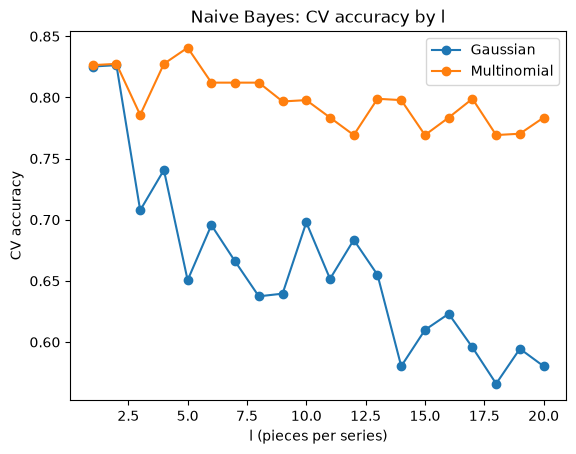

In [33]:
# MultinomialNB needs non-negative features. If any raw reading were negative, some segment's
# min would be negative at l=20, so checking there covers every l.
for t in (train_by_l[20], test_by_l[20]):
    assert (t.drop(columns=label_cols) >= 0).all().all(), 'negative features: MultinomialNB will fail'

nb_summary, nb_curves = [], {}
for name, NB in [('Gaussian', GaussianNB), ('Multinomial', MultinomialNB)]:
    # choose l by stratified 5-fold CV, the same way as before (no scaling or penalty to tune here)
    cv_by_l = {}
    for l in range(1, 21):
        X = train_by_l[l].drop(columns=label_cols)
        y = train_by_l[l]['activity']
        cv_by_l[l] = cross_val_score(NB(), X, y, cv=skf, scoring='accuracy').mean()
    nb_curves[name] = cv_by_l
    l_nb = max(cv_by_l, key=lambda l: (cv_by_l[l], -l))             # best CV accuracy, ties -> smaller l

    Xtr_nb = train_by_l[l_nb].drop(columns=label_cols)
    Xte_nb = test_by_l[l_nb][Xtr_nb.columns]
    model = NB().fit(Xtr_nb, train_by_l[l_nb]['activity'])
    pred_nb = model.predict(Xte_nb)
    yte_nb = test_by_l[l_nb]['activity']
    err = 1 - accuracy_score(yte_nb, pred_nb)

    nb_summary.append({'model': name, 'best l': l_nb, 'CV acc': cv_by_l[l_nb], 'test error': err})
    print(f'--- {name} NB: best l = {l_nb}, test error = {err:.3f} ---')
    print(pd.DataFrame(confusion_matrix(yte_nb, pred_nb, labels=model.classes_),
                       index=model.classes_, columns=model.classes_))

print(pd.DataFrame(nb_summary).round(3))

for name, curve in nb_curves.items():
    plt.plot(list(curve), list(curve.values()), marker='o', label=name)
plt.xlabel('l (pieces per series)')
plt.ylabel('CV accuracy')
plt.title('Naive Bayes: CV accuracy by l')
plt.legend()
plt.show()

#### ii. Comparison

Based on the graph of CV accuracy, Multinomial Naive Bayes is the better model. Conceptually, Multinomial Naive Bayes is specifically designed for non-negative frequency and count measurements. Given that the AReM dataset contains measurements taken from frequency sensors, it makes sense that Multinomial Naive Bayes is better at accommodating the features.

## 3. ISLR 4.8.3

he Bayes classifier assigns an observation with $X = x$ to the class with the largest posterior probability

$$p_k(x) = \frac{\pi_k f_k(x)}{\sum_{l=1}^K \pi_l f_l(x)}, \qquad f_k(x) = \frac{1}{\sqrt{2\pi}\,\sigma_k}\exp\!\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right).$$

The denominator is the same for every class, so we can maximize the numerator, and since $\log$ is increasing, its log:

$$\log\big(\pi_k f_k(x)\big) = \log \pi_k - \log \sigma_k - \tfrac12\log(2\pi) - \frac{(x-\mu_k)^2}{2\sigma_k^2}.$$

The term $-\tfrac12\log(2\pi)$ is the same for all classes, so drop it. Expanding the square gives the discriminant function:

$$\delta_k(x) = -\frac{x^2}{2\sigma_k^2} + \frac{\mu_k}{\sigma_k^2}\,x - \frac{\mu_k^2}{2\sigma_k^2} + \log\pi_k - \log\sigma_k .$$

The Bayes classifier assigns $x$ to $\arg\max_k \delta_k(x)$.

Why it’s quadratic, not linear. In the LDA case from Section 4.4.1, all classes share $\sigma^2$. Then the $-x^2/(2\sigma^2)$ term is identical for every class, so it cancels when comparing classes, leaving a discriminant that is linear in $x$:

$$\delta_k(x) = \frac{\mu_k}{\sigma^2}x - \frac{\mu_k^2}{2\sigma^2} + \log\pi_k.$$

Here the variances differ across classes, so the $x^2$ coefficient $-\frac{1}{2\sigma_k^2}$ differs across classes and doesn’t cancel. The boundary between classes $k$ and $l$ is the set of $x$ where $\delta_k(x) = \delta_l(x)$:

$$\left(\frac{1}{2\sigma_l^2} - \frac{1}{2\sigma_k^2}\right)x^2 + \left(\frac{\mu_k}{\sigma_k^2} - \frac{\mu_l}{\sigma_l^2}\right)x + c_{kl} = 0,$$

where $c_{kl}$ collects the constant terms. If $\sigma_k^2 \neq \sigma_l^2$, the $x^2$ coefficient is nonzero, so this is a genuine quadratic equation in $x$ and the decision boundary is not linear. In other words, $\delta_k(x)$ is a quadratic function of $x$, so the Bayes classifier is quadratic (which is what QDA means). If the variances happen to be equal, the $x^2$ term vanishes and it reduces back to LDA.

## 4. ISLR 4.8.7

Let $Y \in \{\text{Yes}, \text{No}\}$. We’re given:

$\pi_{\text{Yes}} = 0.8$ and $\pi_{\text{No}} = 0.2$
$\mu_{\text{Yes}} = 10$ and $\mu_{\text{No}} = 0$
$\sigma^2 = 36$ for both classes, so $\sigma = 6$

Bayes’ theorem:

$$P(Y=\text{Yes}\mid X=4) = \frac{\pi_{\text{Yes}}\, f_{\text{Yes}}(4)}{\pi_{\text{Yes}}\, f_{\text{Yes}}(4) + \pi_{\text{No}}\, f_{\text{No}}(4)}.$$

The factor $\frac{1}{\sqrt{2\pi}\,\sigma}$ is the same in both densities, so it cancels:

$$P(\text{Yes}\mid X=4) = \frac{0.8\,e^{-(4-10)^2/72}}{0.8\,e^{-(4-10)^2/72} + 0.2\,e^{-(4-0)^2/72}} = \frac{0.8\,e^{-0.5}}{0.8\,e^{-0.5} + 0.2\,e^{-0.2222}}.$$

Numerically, $0.8e^{-0.5} \approx 0.4852$ and $0.2e^{-0.2222} \approx 0.1601$, so

$$P(\text{Yes}\mid X=4) \approx \frac{0.4852}{0.4852 + 0.1601} \approx \mathbf{0.752}.$$

A company with a 4% profit last year has about a 75.2% chance of issuing a dividend. The prior (80% of companies pay dividends) does a lot of the work here: $X=4$ is actually a bit closer to the “No” mean than the “Yes” mean, but the strong prior pulls the posterior toward “Yes”.

## 5.1. Extra Practice ISLR 4.8.4

## 5.2. Extra Practice ISLR 4.8.9